# 08. Transaction – Time theo Label

## Câu hỏi

- Mua càng gần cutoff thì label càng dễ bằng 1 không?
- Khách hoạt động nhiều ngày trong 90 ngày trước cutoff có propensity cao hơn không?
- Hoạt động qua nhiều tuần có liên quan label không?
- Khách có chu kỳ mua ngắn có propensity cao hơn không?
- Khách mua đều có khác khách mua thất thường không?

Tất cả transaction dùng để tạo feature đều nằm trước cutoff. Active days, active weeks và gap được tính trong `[cutoff-90, cutoff-1]`.

## Notebook này làm gì

So sánh temporal behavior giữa Positive và Negative label trong 90 ngày trước cutoff.

### Nội dung đã thực hiện

- Build feature leakage-safe trước cutoff.
- So sánh days since last purchase, active days và active weeks.
- So sánh median interpurchase gap và độ biến thiên gap.
- Vẽ boxplot tổng quát và focused view cho các temporal feature chính.


In [12]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.transaction_time_label import (
    build_focus_boxplot_stats,
    load_transaction_time_label_report,
)
from propensity.eda.transaction_time_label_plots import (
    plot_transaction_time_boxplots,
    plot_transaction_time_focus_boxplots,
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Build leakage-safe temporal features

In [13]:
project_root = Path.cwd().resolve()
if project_root.name in ("notebooks", "draft_notebooks"):
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
transaction_path = project_root / "data" / "raw" / "Dunnhumby" / "transaction_data.csv"

report = load_transaction_time_label_report(
    label_path,
    transaction_path,
    observation_days=90,
)


## 2. Định nghĩa feature

| Feature | Định nghĩa |
|---|---|
| `days_since_last_purchase` | `cutoff_day - last_purchase_day`, dùng toàn bộ lịch sử trước cutoff |
| `active_days_90d` | Số purchase days distinct trong 90 ngày trước cutoff |
| `active_weeks_90d` | Số `WEEK_NO` distinct có mua trong 90 ngày trước cutoff |
| `median_interpurchase_gap_days_90d` | Median gap giữa các purchase days liên tiếp trong cửa sổ |
| `interpurchase_gap_std_days_90d` | Standard deviation của gap; null nếu chưa đủ hai gap |

In [14]:
report.summary_by_label

,feature,label,n_observations,missing_rate,p10,q1,median,q3,p90
0,days_since_last_purchase,0,94821,0.000000,2.000000,5.000000,16.000000,50.000000,128.000000
1,days_since_last_purchase,1,107423,0.000000,1.000000,2.000000,4.000000,9.000000,18.800000
2,active_days_90d,0,94821,0.000000,0.000000,1.000000,4.000000,9.000000,14.000000
3,active_days_90d,1,107423,0.000000,4.000000,8.000000,15.000000,24.000000,36.000000
4,active_weeks_90d,0,94821,0.000000,0.000000,1.000000,4.000000,7.000000,10.000000
5,active_weeks_90d,1,107423,0.000000,4.000000,7.000000,10.000000,12.000000,13.000000
6,median_interpurchase_gap_days_90d,0,70555,0.255914,3.000000,5.000000,8.000000,15.000000,28.000000
7,median_interpurchase_gap_days_90d,1,104628,0.026019,2.000000,3.000000,4.000000,7.000000,12.000000
8,interpurchase_gap_std_days_90d,0,61340,0.353097,2.828427,4.281744,6.968979,11.321194,17.925773
9,interpurchase_gap_std_days_90d,1,102238,0.048267,1.564457,2.308402,3.700776,6.210590,10.263203


## 3. Box plot theo label

Whisker dùng quy tắc 1,5 × IQR. Outlier được hiển thị bằng marker nhỏ với alpha thấp để hạn chế chồng lấn. Mỗi subplot giữ thang đo tự nhiên riêng.

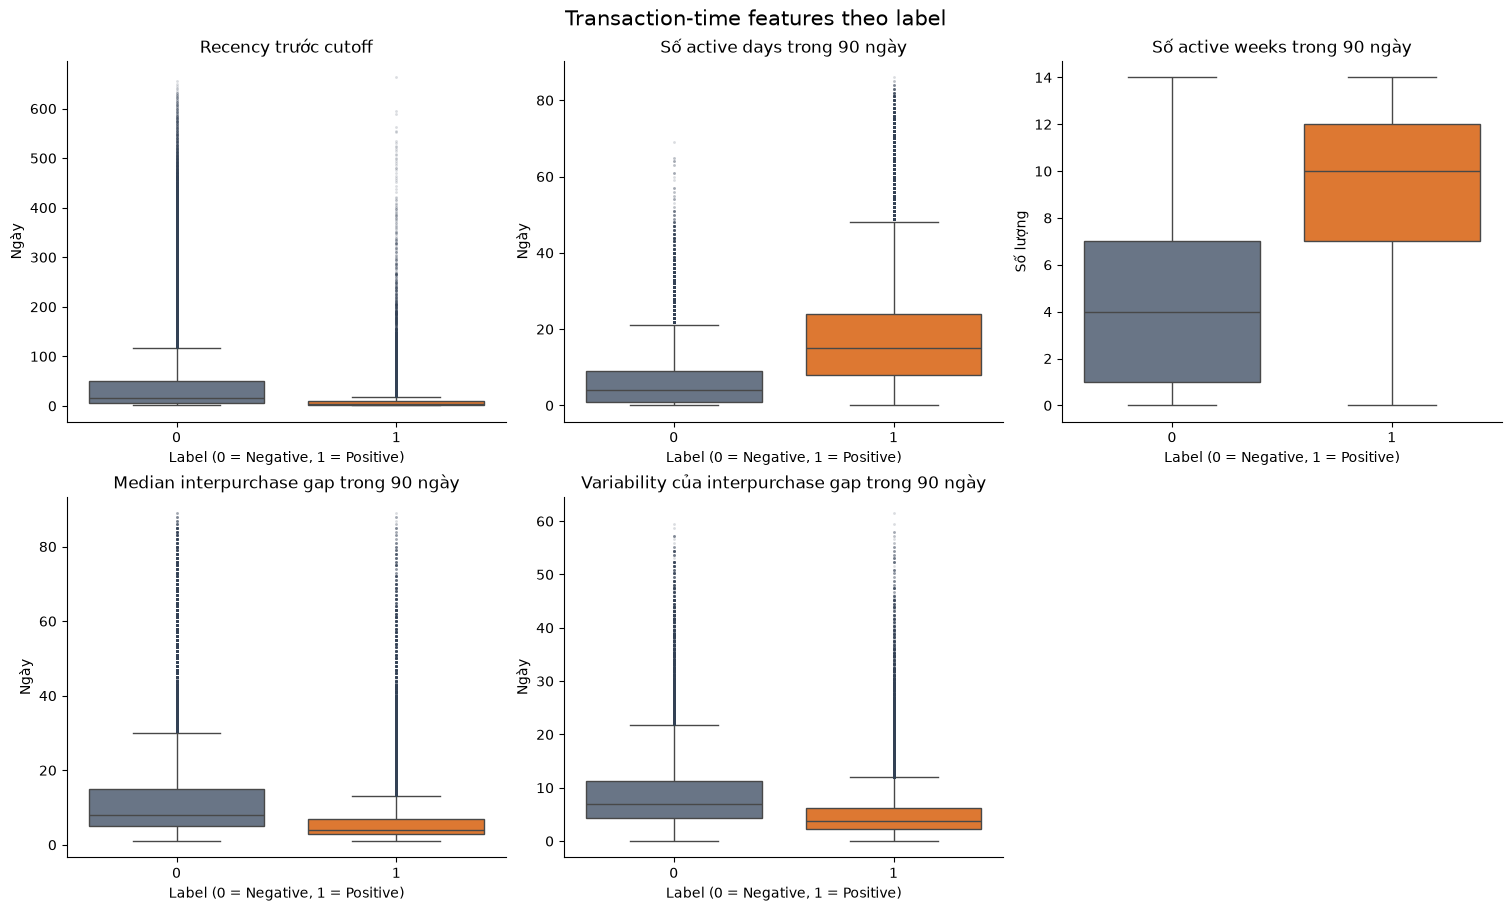

In [15]:
figure = plot_transaction_time_boxplots(report.feature_panel)
plt.show()

## Lưu ý diễn giải

- Gap được tính trên purchase days distinct; nhiều basket cùng ngày không tạo gap bằng 0.
- Gap median cần ít nhất 2 active days; variability cần ít nhất 3 active days. Vì vậy phải đọc `missing_rate` cùng box plot.
- Box plot mô tả association, không chứng minh recency hoặc frequency gây ra label dương.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.

## 4. Focused view: recency, active days và gap variability

Chỉ giữ lại 3 biến trọng tâm. Box plot dùng quy tắc râu 1.5 × IQR và ẩn marker của các điểm ngoại lai để phóng to phần phân phối chính. Bảng bên dưới trả về P25, P75 và râu thực tế theo từng label.

In [16]:
focus_stats = build_focus_boxplot_stats(report.feature_panel)
focus_stats

,feature,label,n_observations,p25,p75,lower_whisker,upper_whisker,n_outliers,outlier_rate
0,days_since_last_purchase,0,94821,5.000000,50.000000,1.0,117.000000,10475,0.110471
1,days_since_last_purchase,1,107423,2.000000,9.000000,1.0,19.000000,10120,0.094207
2,active_days_90d,0,94821,1.000000,9.000000,0.0,21.000000,2729,0.028781
3,active_days_90d,1,107423,8.000000,24.000000,0.0,48.000000,3794,0.035318
4,interpurchase_gap_std_days_90d,0,61340,4.281744,11.321194,0.0,21.856349,3821,0.062292
5,interpurchase_gap_std_days_90d,1,102238,2.308402,6.210590,0.0,12.063489,7272,0.071128


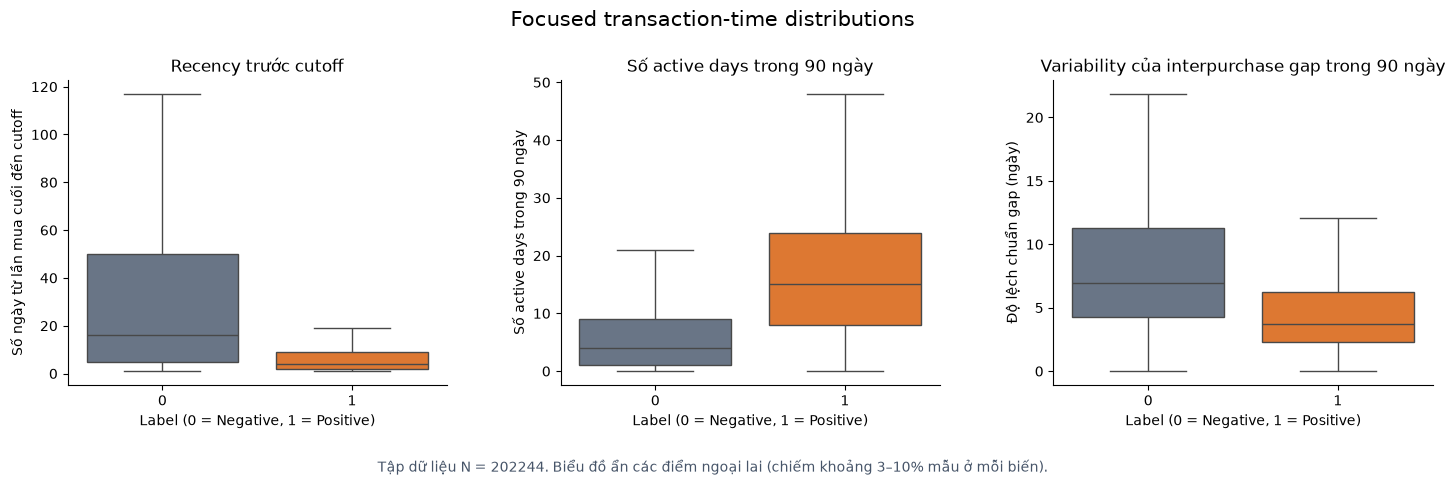

In [17]:
focus_figure = plot_transaction_time_focus_boxplots(report.feature_panel)
plt.show()